**Лабораторна робота №6**

 ФІТ 3-9, Колесник Вікторія

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [2]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [3]:
# Завантаження файлу
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


In [4]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

Вивести інформацію про датасет

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [6]:
print("Frequency of categories in gender:")
print(df["gender"].value_counts())

print("\nRelative frequencies (%):")
print((df["gender"].value_counts(normalize=True) * 100).round(2))


Frequency of categories in gender:
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64

Relative frequencies (%):
gender
Female    58.55
Male      41.43
Other      0.02
Name: proportion, dtype: float64


In [7]:
print("Frequency of categories in smoking_history:")
print(df["smoking_history"].value_counts())

print("\nRelative frequencies (%):")
print((df["smoking_history"].value_counts(normalize=True) * 100).round(2))


Frequency of categories in smoking_history:
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64

Relative frequencies (%):
smoking_history
No Info        35.82
never          35.10
former          9.35
current         9.29
not current     6.45
ever            4.00
Name: proportion, dtype: float64


In [ ]:
# TODO: Кодування категорій зробимо після поділу на train і test.

In [8]:
display(df)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


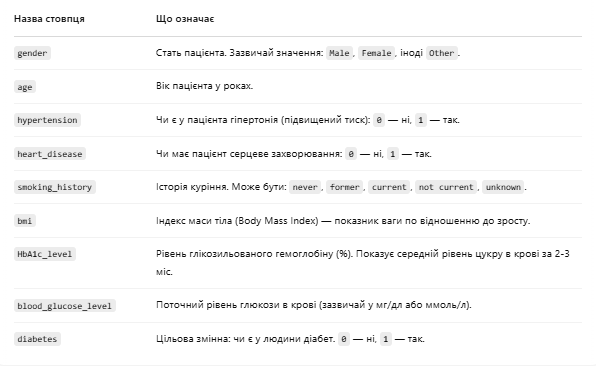

Вивести типи даних

In [9]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [10]:
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом,
чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [11]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [12]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [13]:
df.drop_duplicates(inplace=True)

In [14]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [15]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

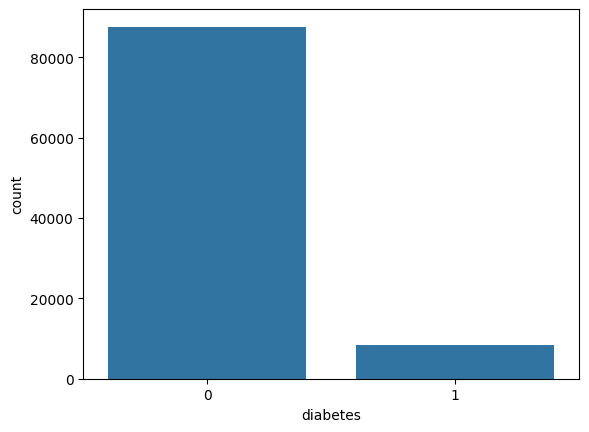

In [16]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [17]:

from sklearn.model_selection import train_test_split

X = df.drop(columns=["diabetes"])
y = df["diabetes"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nClass distribution in training set:")
print(y_train.value_counts())

print("\nClass distribution in test set:")
print(y_test.value_counts())


Training set: (76916, 8)
Test set: (19230, 8)

Class distribution in training set:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Class distribution in test set:
diabetes
0    17534
1     1696
Name: count, dtype: int64


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [18]:
#
categorical_columns = ["gender", "smoking_history"]

X_train = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_columns,
    dtype=int
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

print("\nEncoded columns:")
print(X_train.columns.tolist())

print("\nDo train and test have the same columns?")
print(X_train.columns.equals(X_test.columns))


Training set shape: (76916, 15)
Test set shape: (19230, 15)

Encoded columns:
['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Female', 'gender_Male', 'gender_Other', 'smoking_history_No Info', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']

Do train and test have the same columns?
True


In [19]:
display(X_train.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,76916.0,41.760982,22.467762,0.08,24.00,43.00,59.00,80.00
hypertension,76916.0,0.078007,0.268185,0.00,0.00,0.00,0.00,1.00
heart_disease,76916.0,0.040876,0.198004,0.00,0.00,0.00,0.00,1.00
bmi,76916.0,27.313739,6.757207,10.01,23.39,27.32,29.85,95.22
HbA1c_level,76916.0,5.530527,1.072421,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,76916.0,138.114281,40.896909,80.00,100.00,140.00,159.00,300.00
gender_Female,76916.0,0.582675,0.493121,0.00,0.00,1.00,1.00,1.00
gender_Male,76916.0,0.417143,0.493090,0.00,0.00,0.00,1.00,1.00
gender_Other,76916.0,0.000182,0.013490,0.00,0.00,0.00,0.00,1.00
smoking_history_No Info,76916.0,0.342022,0.474390,0.00,0.00,0.00,1.00,1.00


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [20]:
target_correlation = X_train.corrwith(y_train).sort_values(
    ascending=False
)

display(target_correlation.to_frame(name="Correlation"))


,Correlation
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725
smoking_history_ever,0.020899


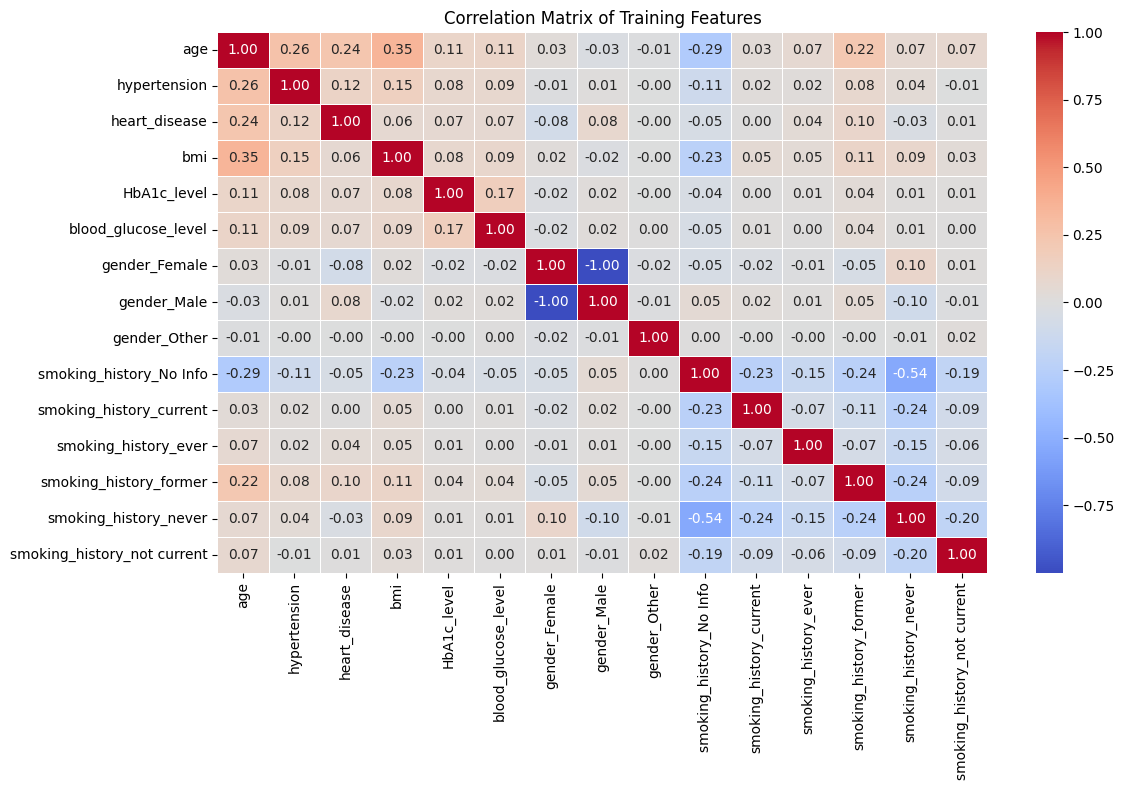

In [22]:
correlation_matrix = X_train.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Training Features")
plt.tight_layout()
plt.show()


**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Висновок: за результатами кореляційного аналізу навчальної вибірки можна визначити, які ознаки мають найсильніший зв’язок із цільовою змінною diabetes, а також чи існує сильна кореляція між самими ознаками. Ознаки з найбільшою позитивною кореляцією з diabetes можуть бути найбільш інформативними для прогнозування діабету. Якщо між двома ознаками спостерігається сильна кореляція, це може свідчити про мультиколінеарність. Проте видаляти ознаки лише на основі кореляції не обов’язково, оскільки вони можуть містити корисну інформацію для моделей. Тому на цьому етапі доцільно залишити всі ознаки та порівняти якість моделей, а рішення щодо їх видалення приймати за результатами аналізу навчальних даних. Тестову вибірку для такого рішення не використовуємо.

Перевірити викиди **лише на навчальній вибірці**

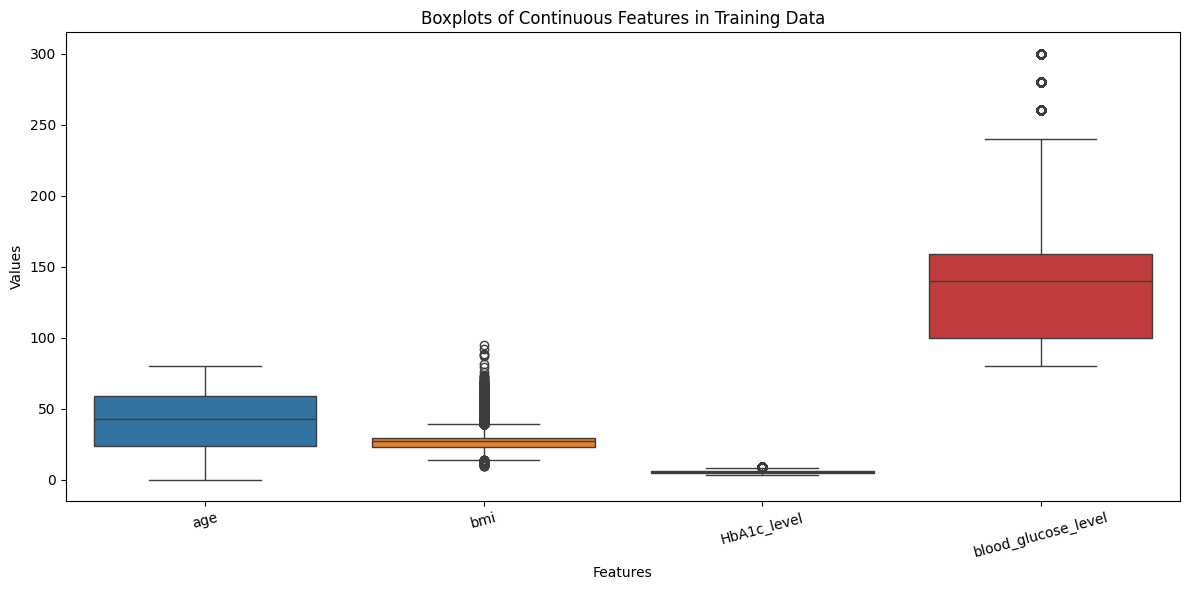

In [23]:
continuous_cols = [
    "age",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level"
]

plt.figure(figsize=(12, 6))

sns.boxplot(data=X_train[continuous_cols])

plt.title("Boxplots of Continuous Features in Training Data")
plt.xlabel("Features")
plt.ylabel("Values")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [24]:
skewness = X_train[continuous_cols].skew()

display(skewness.to_frame(name="Skewness"))

,Skewness
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [25]:
print("Missing values in X_train:")
display(X_train.isnull().sum().to_frame(name="Missing values"))

print("Missing values in X_test:")
display(X_test.isnull().sum().to_frame(name="Missing values"))

Missing values in X_train:


,Missing values
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


Missing values in X_test:


,Missing values
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender_Female,0
gender_Male,0
gender_Other,0
smoking_history_No Info,0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

У датасеті спостерігається дисбаланс класів: 91,5% записів без діабету та 8,5% із діабетом. Найсильнішу позитивну кореляцію з цільовою змінною мають blood_glucose_level (0,423) і HbA1c_level (0,405). Розподіли age та HbA1c_level приблизно симетричні, тоді як bmi і blood_glucose_level мають правосторонню асиметрію. На навчальній вибірці перевірено можливі викиди, які не слід видаляти без додаткового аналізу. Пропущених значень у тренувальній і тестовій вибірках немає. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [27]:
from imblearn.over_sampling import SMOTE
from collections import Counter

print("Class counts before SMOTE:")
print(Counter(y_train))

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled, y_train
)

print("\nClass counts after SMOTE:")
print(Counter(y_train_balanced))

Class counts before SMOTE:
Counter({0: 70130, 1: 6786})

Class counts after SMOTE:
Counter({0: 70130, 1: 70130})


Оголошуємо моделі

In [28]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC

models = {
    "LogisticRegression": LogisticRegression(
        C=1.0, solver="lbfgs", max_iter=1000, random_state=42
    ),
    "RidgeClassifier": RidgeClassifier(alpha=1.0),
    "SGDClassifier": SGDClassifier(
        loss="hinge", penalty="l2", max_iter=1000, random_state=42
    ),
    "SVC": SVC(C=1.0, kernel="rbf", random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Model: LogisticRegression

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



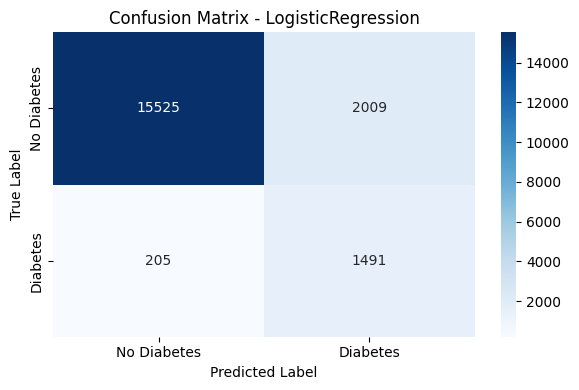


Model: RidgeClassifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



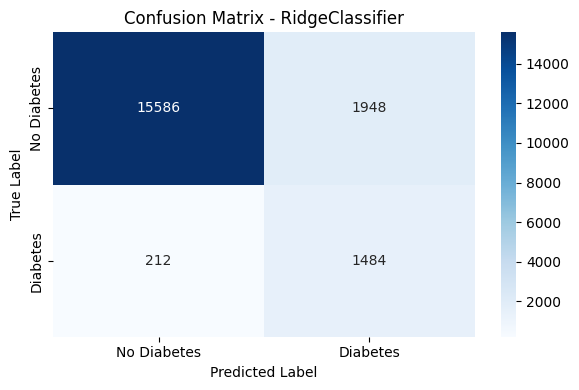


Model: SGDClassifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



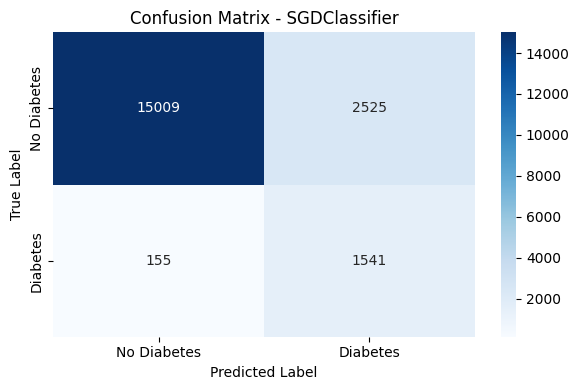


Model: SVC

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



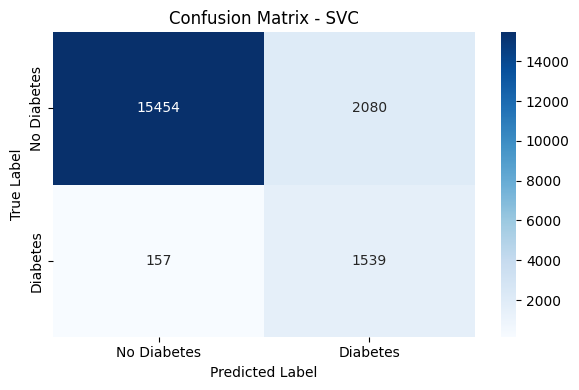

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

results = {}

for name, model in models.items():
    print(f"\n{'=' * 50}")
    print(f"Model: {name}")
    print("=" * 50)

    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test_scaled)

    results[name] = {
        "model": model,
        "predictions": y_pred
    }

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Diabetes", "Diabetes"],
        yticklabels=["No Diabetes", "Diabetes"]
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.tight_layout()
    plt.show()

Оптимізувати гіперпараметри


In [30]:
param_grids = {
    "LogisticRegression": {
        "C": [0.1, 1.0, 10.0],
        "solver": ["lbfgs"]
    },
    "RidgeClassifier": {
        "alpha": [0.1, 1.0, 10.0]
    },
    "SGDClassifier": {
        "loss": ["hinge", "log_loss"],
        "penalty": ["l2", "l1"],
        "alpha": [0.0001, 0.001]
    },
    "SVC": {
        "C": [0.1, 1.0],
        "kernel": ["linear", "rbf"]
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [31]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [32]:
from sklearn.metrics import classification_report

best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\n{'=' * 60}")
    print(f"Optimizing: {name}")
    print("=" * 60)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    model_param_grid = {
        f"model__{param}": values
        for param, values in param_grids[name].items()
    }

    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=model_param_grid,
        cv=3,
        scoring="f1",
        min_resources=300,
        factor=3,
        n_jobs=-1,
        random_state=42
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print("\nBest parameters:")
    print(search.best_params_)

    print(f"\nBest cross-validation F1: {search.best_score_:.4f}")

    y_pred = search.best_estimator_.predict(X_test)

    print("\nClassification Report on Test Set:")
    print(classification_report(y_test, y_pred, zero_division=0))


Optimizing: LogisticRegression

Best parameters:
{'model__C': 1.0, 'model__solver': 'lbfgs'}

Best cross-validation F1: 0.6098

Classification Report on Test Set:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230


Optimizing: RidgeClassifier

Best parameters:
{'model__alpha': 10.0}

Best cross-validation F1: 0.6516

Classification Report on Test Set:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


Optimizing: SGDClassifier

Best parameter

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [33]:
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]

print("Best model:", best_model_name)
print(f"Mean cross-validation F1: {best_scores[best_model_name]:.4f}")

Best model: RidgeClassifier
Mean cross-validation F1: 0.6516


In [34]:
import pandas as pd

random_indices = X_test.sample(
    n=10,
    random_state=42
).index

X_sample = X_test.loc[random_indices]
y_sample = y_test.loc[random_indices]
y_pred_sample = best_model.predict(X_sample)

comparison = pd.DataFrame({
    "Index": random_indices,
    "True Class": y_sample.to_numpy(),
    "Predicted Class": y_pred_sample
})

display(comparison)

,Index,True Class,Predicted Class
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

**1**.У наборі даних спостерігався значний дисбаланс класів: приблизно 91,2% об’єктів належать до класу diabetes = 0, а 8,8% — до класу diabetes = 1. Для компенсації дисбалансу на навчальній вибірці застосовано метод SMOTE. Кореляційний аналіз показав, що найбільший позитивний зв’язок із цільовою змінною мають рівень глюкози в крові (blood_glucose_level, 0,423) та рівень HbA1c (HbA1c_level, 0,405). Також помітний зв’язок спостерігається з віком і BMI. Перевірка викидів за допомогою boxplot на навчальній вибірці виявила потенційно аномальні значення в числових ознаках, особливо в BMI та рівні глюкози. Проте такі значення не обов’язково є помилковими, тому їх не слід автоматично видаляти    


**2**.Серед початкових моделей найкращі значення F1 для класу diabetes = 1 показали RidgeClassifier і SVC — приблизно 0,58. Найвищий Recall отримали SGDClassifier і SVC — 0,91, тобто вони виявляють більшу частину об’єктів із діабетом. Після підбору гіперпараметрів найкращою моделлю за середнім F1 на кросвалідації стала RidgeClassifier із результатом 0,6516. На тестовій вибірці вона отримала F1 = 0,58 і Recall = 0,88 для класу diabetes = 1.


**3**.Під час підбору гіперпараметрів отримано такі результати:

LogisticRegression: C = 1.0, solver = 'lbfgs'; F1 кросвалідації — 0,6098.

RidgeClassifier: alpha = 10.0; F1 кросвалідації — 0,6516.

SGDClassifier: alpha = 0.001, loss = 'log_loss', penalty = 'l1'; F1 кросвалідації — 0,6179.

SVC: C = 0.1, kernel = 'linear'; F1 кросвалідації — 0,6001.

Отже, найкращий результат за кросвалідацією показала модель RidgeClassifier. За звітами класифікації видно, що для класу diabetes = 1 точність (precision) становить приблизно 0,42–0,43, а повнота (recall) — 0,88–0,89 у налаштованих моделях. Це означає, що моделі виявляють більшість випадків діабету, але водночас помилково відносять частину людей без діабету до позитивного класу. Також залишаються випадки діабету, які моделі не виявляють. Тому для оцінювання важливо враховувати не лише accuracy, а й F1 та recall для позитивного класу.


**4**.Тестова вибірка відокремлюється для об’єктивної оцінки якості моделі на даних, які не використовувалися під час її навчання. Масштабування навчається лише на навчальних даних, після чого ті самі параметри перетворення застосовуються до тестової вибірки. Це запобігає витоку інформації з тестових даних. SMOTE також застосовується тільки до навчальної вибірки, щоб збалансувати класи без штучного збільшення кількості позитивних прикладів у тесті. Завдяки цьому тестування краще відображає здатність моделі працювати з реальними даними та дозволяє отримати більш об’єктивні результати оцінювання.
